# Phase 1 — synthetic waveform CNN detection
## 1. Scope and reference
**Experiment A: earthquake versus noise detection from an existing waveform. This is not future forecasting.** Preserve the separate `phase1_cnn_forecasting.ipynb` and its results. No BiLSTM is trained.

[Perol, Gharbi & Denolle (2018)](https://doi.org/10.1126/sciadv.1700578), [author project](https://groups.csail.mit.edu/graphics/convnetquake/), [author preprint](https://arxiv.org/pdf/1702.02073) motivate convolutional waveform feature extraction. Their three-component, 10-second input and noise/location categories differ from our single vertical, 100-second synthetic input and binary labels. Adopt local filters, downsampling, nonlinear feature extraction and regularization, not their performance claims or location identifiability.

The eleven-stage simulator was already indexed in the earlier audit. Stages 1–2 validate metadata and calculate theoretical travel times; 3–4 synthesize and attenuate/noise wave packets; 5–7 evaluate prototypes, generate full traces and perform QC; 8 improves attenuation/envelopes/SNR; 9 generates the improved full catalog; 10 adds matched stochastic noise; 11 makes pair-aware stratified detection splits and normalized arrays. We reuse those existing files without regenerating them.

## 2. Reproducibility and configuration
Fixed seed and deterministic PyTorch operations; CUDA if available. The full 10,000 samples enter the model. Use provided per-trace detrended standardization to reduce raw amplitude shortcuts. It uses the completed input trace and is valid for offline detection, not pre-event forecasting or a causal real-time detector. Read small HDF5 chunks into CPU memory, transfer minibatches only. The audit is a prerequisite and records full-array numerical and exact-duplicate checks, sampled upstream alignment, and metadata joins.

In [1]:
from pathlib import Path
import os,sys,json,hashlib,random,time,platform,importlib.metadata
import numpy as np
import pandas as pd
import h5py
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,
    average_precision_score,precision_recall_curve,roc_curve,auc,confusion_matrix,log_loss)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from IPython.display import display,Image
BASE=Path.cwd()
if not (BASE/'data wave').is_dir():BASE=BASE/'cnn'/'cnn wave'
RES=BASE/'phase1_waveform_cnn_results';MEM=BASE/'.agent-memory'
AUDIT=json.loads((RES/'reports'/'waveform_audit.json').read_text())
PATHS={s:BASE/AUDIT['splits'][s]['path'] for s in ['train','validation','test']}
CONFIG=dict(version='waveform-detection-v1',seed=42,waveform_key='waveforms_standardized',
    input_samples=10000,sampling_hz=100,batch_size=32,hdf5_block_rows=100,filters=[8,16,32],
    kernels=[9,7,5],strides=[2,2,1],pool_size=4,dropout=.3,learning_rate=.001,
    weight_decay=.0001,max_epochs=25,patience=5,threshold=.5)
dataset_version=hashlib.sha256(json.dumps(AUDIT['source_hashes'],sort_keys=True).encode()).hexdigest()
EID='wavecnn_'+hashlib.sha256((dataset_version+json.dumps(CONFIG,sort_keys=True)).encode()).hexdigest()[:12]
D={k:RES/k/EID for k in ['models','metrics','plots','reports']}
for p in D.values():p.mkdir(parents=True,exist_ok=True)
def save(path,obj):path.write_text(json.dumps(obj,indent=2,default=str,allow_nan=False),encoding='utf-8')
def sha(path):
    h=hashlib.sha256()
    with path.open('rb') as f:
        for block in iter(lambda:f.read(8*1024*1024),b''):h.update(block)
    return h.hexdigest()
def figure(name):
    plt.tight_layout();plt.savefig(D['plots']/name,dpi=140,bbox_inches='tight');plt.close()
    display(Image(filename=str(D['plots']/name)))
def memory(message):
    (MEM/'checkpoint.md').write_text('# Waveform checkpoint — 2026-11-05\n'+message+'\n',encoding='utf-8')
os.environ['CUBLAS_WORKSPACE_CONFIG']=':4096:8'
random.seed(42);np.random.seed(42);torch.manual_seed(42);torch.set_num_threads(4)
if torch.cuda.is_available():torch.cuda.manual_seed_all(42)
torch.backends.cudnn.deterministic=True;torch.backends.cudnn.benchmark=False
torch.use_deterministic_algorithms(True)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
environment={p:importlib.metadata.version(p) for p in ['torch','numpy','pandas','scikit-learn','h5py','scipy','matplotlib','nbformat','nbclient','ipykernel']}
environment.update(python=platform.python_version(),device=str(DEVICE),gpu=torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else None)
save(D['reports']/'environment.json',environment);save(D['reports']/'config.json',CONFIG)
print(EID,environment['gpu'] or 'CPU')

wavecnn_ccb3b06b3d37 NVIDIA GeForce RTX 3050 Laptop GPU


## 3. Verified dataset and labels
Read `train.h5`, `validation.h5`, `test.h5` from `output/phase11_preprocessed_dataset`. Each waveform is 10,000 float32 samples at 100 Hz (100 s). Labels are 1=synthetic earthquake and 0=synthetic noise. There are 5,662/1,213/1,214 matched pairs respectively; each pair's earthquake and noise remain together. These are random stratified, source/pair-disjoint splits suitable for an in-simulator detection benchmark, not a temporal forecasting evaluation.

HDF5 includes magnitude, depth, hypocentral distance, P/S arrival sample, SNR, QC, receiver/source/trace identifiers and pair IDs. **HDF5 does not contain origin timestamps or latitude/longitude.** Those join uniquely by earthquake source ID to Phase 2 metadata. Noise has no earthquake magnitude/origin/location and has arrival sentinel −1; never use those metadata fields as model inputs. QC failures are retained and evaluated separately.

Audit checks: all 16,178 raw and standardized traces finite/nonzero; every label/source/pair mapping checked; no exact raw/normalized duplicates or duplicate physical event keys; full-array normalized moments; training global scale independently recalculated; 12 traces per split checked against normalization formulas and Phase 10/9 origins. No exhaustive near-duplicate correlation test was performed. Shared simulator templates and acquisition assumptions remain a dependence risk despite unique bytes.

In [2]:
for rel,digest in AUDIT['source_hashes'].items():assert sha(BASE/rel)==digest,'Source changed: refresh audit'
META=pd.read_csv(RES/'reports'/'verified_metadata.csv')
FEATURES=pd.read_csv(RES/'reports'/'signal_features.csv')
assert all(AUDIT['checks'][k] for k in ['all_waveforms_finite_nonzero','all_labels_and_mapping_aligned','pairs_and_sources_disjoint','no_duplicate_event_keys','no_exact_raw_or_standardized_duplicates'])
labels={};metas={}
for s,p in PATHS.items():
    with h5py.File(p,'r') as f:
        labels[s]=f['labels'][:].astype(np.float32)
        assert f[CONFIG['waveform_key']].shape==(len(labels[s]),10000)
        half=len(labels[s])//2
        assert (labels[s][:half]==1).all() and (labels[s][half:]==0).all()
    metas[s]=META[META.split.eq(s)].sort_values('row').reset_index(drop=True)
    assert np.array_equal(labels[s],metas[s].labels)
display(pd.DataFrame([dict(split=s,shape=str(AUDIT['splits'][s]['shape']),earthquakes=int(labels[s].sum()),noise=int((labels[s]==0).sum()),origin_min=AUDIT['splits'][s]['origin_min'],origin_max=AUDIT['splits'][s]['origin_max']) for s in PATHS]))
save(D['models']/'preprocessing.json',dict(input_key=CONFIG['waveform_key'],input_shape=[10000,1],pytorch_shape=[1,10000],
    labels={'0':'synthetic noise','1':'synthetic earthquake'},normalization=AUDIT['normalization'],
    inference='Linear detrend entire trace, subtract per-trace mean, divide by per-trace std + 1e-8.',metadata_inputs=False))
print('P arrival ranges:',{s:AUDIT['splits'][s]['p_arrival_range'] for s in PATHS})
memory(f'W1/W2 verified; W3 implementation ready. {EID}. Next: real GPU waveform training. Catalog outputs preserved.')

,split,shape,earthquakes,noise,origin_min,origin_max
0,train,"[11324, 10000]",5662,5662,1908-12-12 12:54:09+00:00,2026-10-06 09:03:32+00:00
1,validation,"[2426, 10000]",1213,1213,1906-08-31 14:57:30+00:00,2026-10-05 22:57:25+00:00
2,test,"[2428, 10000]",1214,1214,1922-12-24 00:06:26+00:00,2026-10-05 22:53:47+00:00


P arrival ranges: {'train': [592, 607], 'validation': [594, 607], 'test': [593, 606]}


## 4. Experiment B — parameter-estimation feasibility
- **Magnitude:** verified earthquake labels exist. Absolute amplitude is lost under per-trace normalization; envelope duration and spectral/shape properties still depend on the generator's magnitude formula. A regression could learn that inverse simulator relationship, not establish empirical magnitude estimation. Raw amplitude also confounds magnitude, distance, attenuation and prescribed SNR.
- **Time:** source UTC timestamps join correctly, but the trace has no absolute clock. Calendar origin time is unidentifiable. Relative P/S picks exist, but P is anchored near six seconds; a constant-pick baseline would be essential before claiming arrival-time skill.
- **Location:** coordinates join correctly, but one vertical synthetic trace without receiver coordinates, azimuth information or multiple stations does not uniquely determine latitude/longitude. S−P may constrain modeled distance; many possible locations share that distance. A model might learn catalog/station or generator priors instead.

Therefore **Experiment B is investigated but not trained** in this baseline. Valid metadata alone does not demonstrate unique information in the chosen input. A separately scoped simulator-parameter inversion or arrival-picking study would require appropriate baselines and independent real recordings. Detection results below must not be presented as parameter-estimation or pre-event forecasting performance.

## 5. Waveform exploration
Show examples and signal-property distributions without feeding metadata into the CNN. The provided 50/50 class balance is artificial; precision and calibrated probabilities will change under field prevalence. Shared synthetic noise types, narrow harmonics, fixed onset and envelope rules may make the task much easier than real seismology.

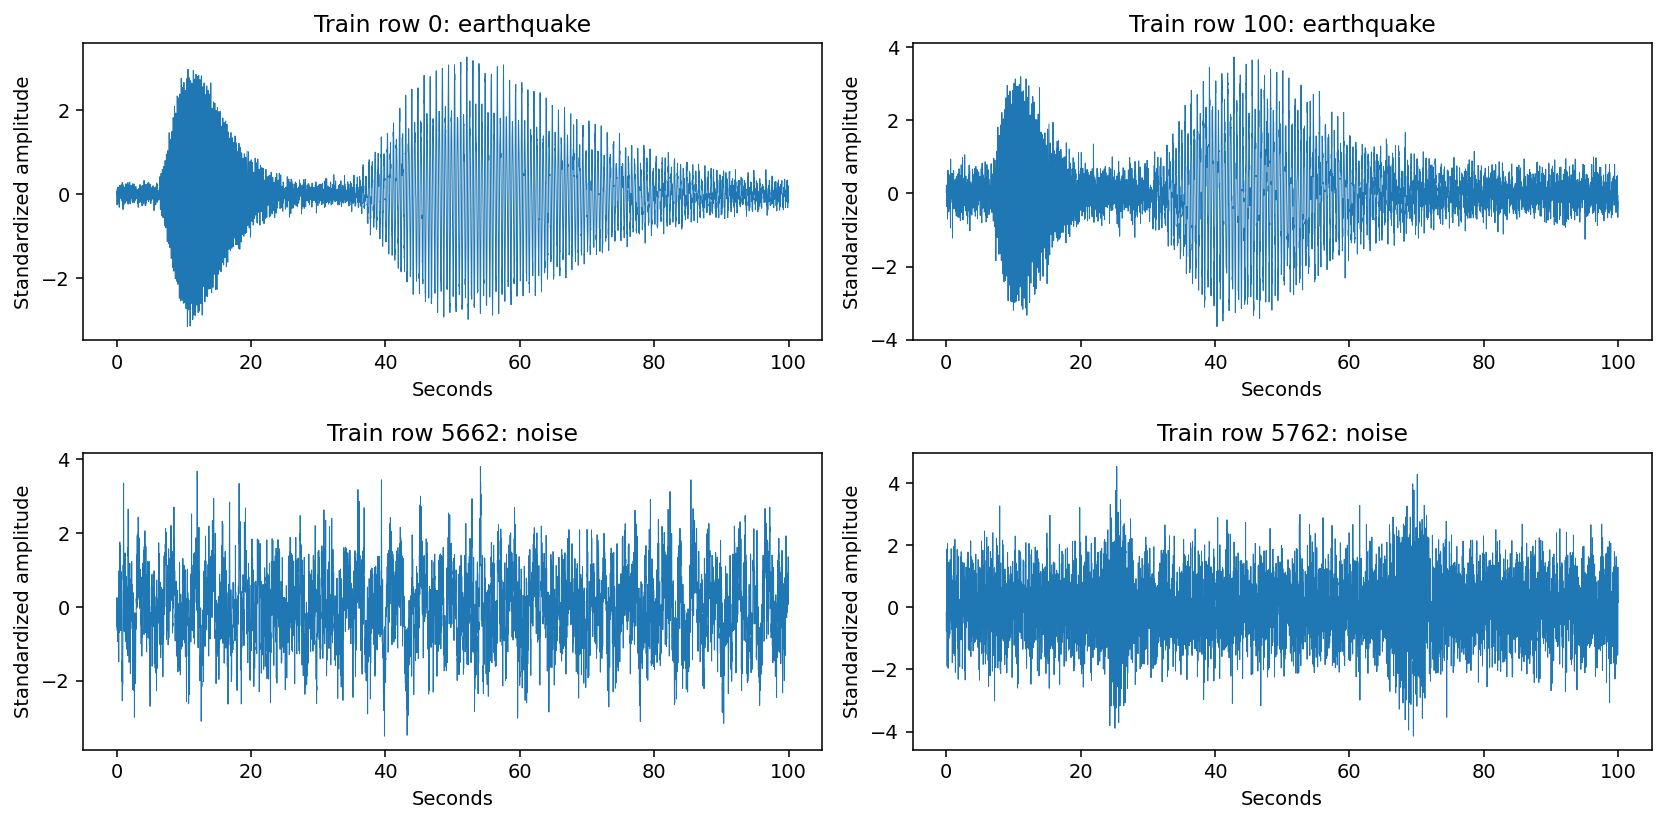

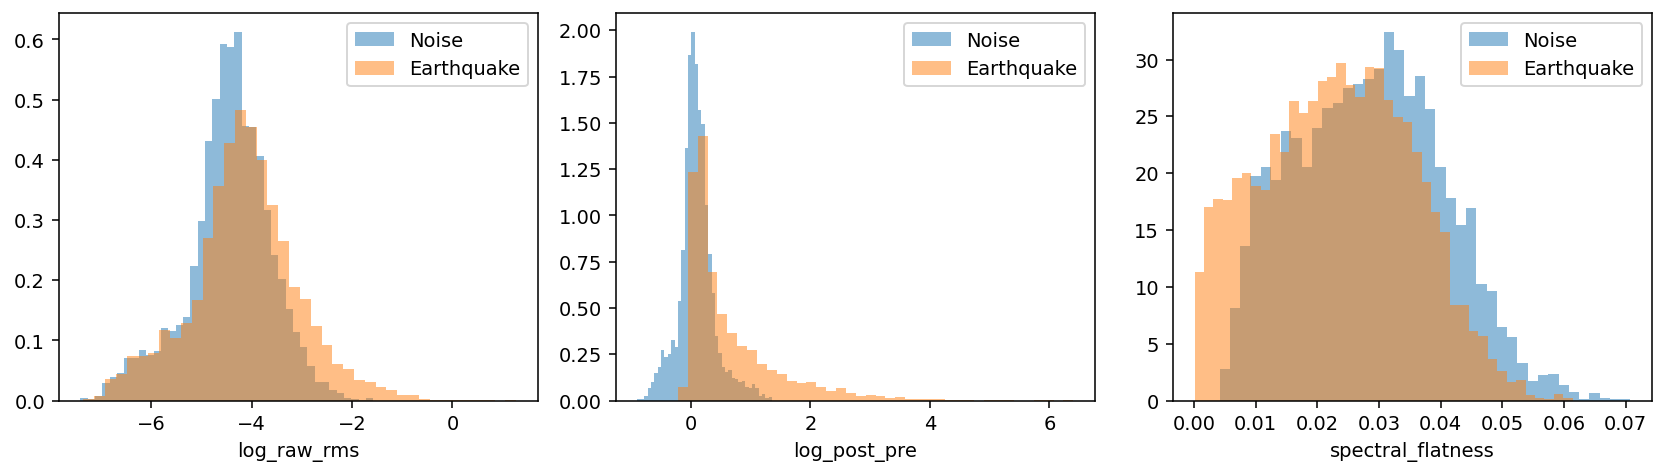

In [3]:
fig,axes=plt.subplots(2,2,figsize=(12,6))
with h5py.File(PATHS['train'],'r') as f:
    for ax,row in zip(axes.flat,[0,100,len(labels['train'])//2,len(labels['train'])//2+100]):
        x=f[CONFIG['waveform_key']][row]
        ax.plot(np.arange(10000)/100,x,lw=.5)
        ax.set(title=f'Train row {row}: '+('earthquake' if labels['train'][row] else 'noise'),xlabel='Seconds',ylabel='Standardized amplitude')
figure('waveform_examples.png')
fig,axes=plt.subplots(1,3,figsize=(12,3.5))
train_features=FEATURES[FEATURES.split.eq('train')]
for ax,col in zip(axes,['log_raw_rms','log_post_pre','spectral_flatness']):
    for label,title in [(0,'Noise'),(1,'Earthquake')]:ax.hist(train_features.loc[train_features.label.eq(label),col],bins=40,alpha=.5,density=True,label=title)
    ax.set_xlabel(col);ax.legend()
figure('signal_property_distributions.png')

## 6. Memory-efficient loading and CNN
HDF5 chunks contain 100 rows. Read one 100-row earthquake block and its corresponding noise block, shuffle within this small CPU buffer, then yield batches of 32. Also shuffle block order each epoch. This avoids large random decompression costs and homogeneous-class batches from the class-ordered file. No entire waveform dataset is loaded on the GPU. All samples are visited exactly once each epoch, including the remainder.

Input tensor (batch,1,10000) → Conv1D(1→8,k9,stride2,pad4)/BN/ReLU → MaxPool4 → Conv1D(8→16,k7,stride2,pad3)/BN/ReLU → MaxPool4 → Conv1D(16→32,k5,pad2)/ReLU → global average → Dense32→16/ReLU/Dropout0.3 → one logit. Sigmoid gives P(earthquake). Filters detect local oscillatory/envelope features; downsampling reduces cost; global pooling summarizes the trace. It is not a time-localized onset picker.

## 7. Training protocol
Unweighted BCEWithLogitsLoss, AdamW lr=0.001/decay=0.0001, at most 25 epochs, early stopping after five validation-loss non-improvements. Halve learning rate after two stagnant epochs. Fixed classification threshold 0.5, never adjusted on test. Save best and last model, optimizer/scheduler/RNG state and history. The epoch-derived block shuffle is reproducible. Re-executing a completed configuration restores weights instead of retraining. Test evaluation occurs only after checkpoint selection.

In [4]:
def batches(split,epoch=0,shuffle=False):
    n=len(labels[split]);half=n//2;block=CONFIG['hdf5_block_rows'];rng=np.random.default_rng(CONFIG['seed']+epoch)
    order=np.arange(0,half,block)
    if shuffle:rng.shuffle(order)
    with h5py.File(PATHS[split],'r',rdcc_nbytes=32*1024*1024) as f:
        for start in order:
            stop=min(start+block,half)
            rows=np.r_[np.arange(start,stop),np.arange(half+start,half+stop)]
            x=np.concatenate([f[CONFIG['waveform_key']][start:stop],f[CONFIG['waveform_key']][half+start:half+stop]])
            order2=np.arange(len(rows))
            if shuffle:rng.shuffle(order2)
            for j in range(0,len(rows),CONFIG['batch_size']):
                sel=order2[j:j+CONFIG['batch_size']];rr=rows[sel]
                yield torch.from_numpy(x[sel,None,:].copy()),torch.from_numpy(labels[split][rr,None].copy()),rr
class WaveformCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv=nn.Sequential(nn.Conv1d(1,8,9,stride=2,padding=4),nn.BatchNorm1d(8),nn.ReLU(),nn.MaxPool1d(4),
            nn.Conv1d(8,16,7,stride=2,padding=3),nn.BatchNorm1d(16),nn.ReLU(),nn.MaxPool1d(4),
            nn.Conv1d(16,32,5,padding=2),nn.ReLU(),nn.AdaptiveAvgPool1d(1))
        self.head=nn.Sequential(nn.Flatten(),nn.Linear(32,16),nn.ReLU(),nn.Dropout(.3),nn.Linear(16,1))
    def forward(self,x):return self.head(self.conv(x))
model=WaveformCNN().to(DEVICE)
model.eval()
with torch.no_grad():assert model(torch.zeros(2,1,10000,device=DEVICE)).shape==(2,1)
PARAMETERS=sum(p.numel() for p in model.parameters() if p.requires_grad)
loss_fn=nn.BCEWithLogitsLoss()
optimizer=torch.optim.AdamW(model.parameters(),lr=CONFIG['learning_rate'],weight_decay=CONFIG['weight_decay'])
scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='min',factor=.5,patience=2)
def evaluate(split,transform=None):
    model.eval();probs=np.empty(len(labels[split]),dtype=np.float64);total=0.;seen=np.zeros(len(probs),dtype=int)
    with torch.no_grad():
        for x,y,rows in batches(split):
            if transform is not None:x=transform(x,rows)
            logits=model(x.to(DEVICE));total+=loss_fn(logits,y.to(DEVICE)).item()*len(rows)
            probs[rows]=torch.sigmoid(logits).cpu().numpy().ravel();seen[rows]+=1
    assert (seen==1).all() and np.isfinite(probs).all()
    return total/len(probs),probs
print(model);print('Trainable parameters:',PARAMETERS)
(D['reports']/'architecture.txt').write_text(str(model)+f'\nParameters: {PARAMETERS}\n',encoding='utf-8')

WaveformCNN(
  (conv): Sequential(
    (0): Conv1d(1, 8, kernel_size=(9,), stride=(2,), padding=(4,))
    (1): BatchNorm1d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(8, 16, kernel_size=(7,), stride=(2,), padding=(3,))
    (5): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
    (8): Conv1d(16, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (9): ReLU()
    (10): AdaptiveAvgPool1d(output_size=1)
  )
  (head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=32, out_features=16, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)
Trainable parameters: 4177


940

In [5]:
best_path=D['models']/'best.pt';last_path=D['models']/'last.pt'
history=[];best=float('inf');stale=0;start_epoch=1;complete=False
if last_path.exists():
    state=torch.load(last_path,map_location=DEVICE,weights_only=False)
    assert state['config']==CONFIG and state['dataset_version']==dataset_version
    model.load_state_dict(state['model']);optimizer.load_state_dict(state['optimizer']);scheduler.load_state_dict(state['scheduler'])
    history=state['history'];best=state['best'];stale=state['stale'];start_epoch=state['epoch']+1;complete=state['complete']
    random.setstate(state['python_rng']);np.random.set_state(state['numpy_rng']);torch.set_rng_state(state['torch_rng'].cpu())
    if DEVICE.type=='cuda' and state['cuda_rng'] is not None:torch.cuda.set_rng_state_all([r.cpu() for r in state['cuda_rng']])
    print('Restored epoch',state['epoch'],'completed:',complete)
registry=json.loads((MEM/'experiment_registry.json').read_text())
entry=dict(experiment_id=EID,model_type='1D waveform CNN detection',dataset_version=dataset_version,
    dataset_files={s:str(p.relative_to(BASE)) for s,p in PATHS.items()},input_features=['standardized vertical waveform'],
    input_shape=[10000,1],output='earthquake/noise probability',forecast_horizon=None,
    split_method='provided Phase 11 paired stratified splits; not chronological',date_ranges={s:[AUDIT['splits'][s]['origin_min'],AUDIT['splits'][s]['origin_max']] for s in PATHS},
    hyperparameters=CONFIG,random_seed=42,model_checkpoint_path=str(best_path.relative_to(BASE)),metrics_path=str((D['metrics']/'detection_metrics.csv').relative_to(BASE)),experiment_status='training')
registry['experiments']=[e for e in registry['experiments'] if e['experiment_id']!=EID]+[entry]
save(MEM/'experiment_registry.json',registry)
for epoch in ([] if complete else range(start_epoch,CONFIG['max_epochs']+1)):
    tic=time.perf_counter();model.train();total=0.;correct=0;seen=np.zeros(len(labels['train']),dtype=int)
    for x,y,rows in batches('train',epoch,True):
        x=x.to(DEVICE);y=y.to(DEVICE);optimizer.zero_grad(set_to_none=True)
        logits=model(x);loss=loss_fn(logits,y);loss.backward();optimizer.step()
        total+=loss.item()*len(rows);correct+=int(((logits>=0)==(y>=.5)).sum().item());seen[rows]+=1
    assert (seen==1).all()
    val_loss,vp=evaluate('validation')
    assert np.isfinite(val_loss)
    if val_loss<best-1e-5:
        best=val_loss;stale=0
        torch.save(dict(model=model.state_dict(),epoch=epoch,val_loss=best,config=CONFIG,dataset_version=dataset_version),best_path)
    else:stale+=1
    scheduler.step(val_loss)
    history.append(dict(epoch=epoch,train_loss=total/len(labels['train']),train_accuracy=correct/len(labels['train']),
        validation_loss=val_loss,validation_accuracy=float(accuracy_score(labels['validation'],vp>=.5)),
        learning_rate=optimizer.param_groups[0]['lr'],seconds=time.perf_counter()-tic))
    complete=stale>=CONFIG['patience'] or epoch==CONFIG['max_epochs']
    state=dict(model=model.state_dict(),optimizer=optimizer.state_dict(),scheduler=scheduler.state_dict(),epoch=epoch,
        history=history,best=best,stale=stale,complete=complete,config=CONFIG,dataset_version=dataset_version,
        python_rng=random.getstate(),numpy_rng=np.random.get_state(),torch_rng=torch.get_rng_state(),cuda_rng=torch.cuda.get_rng_state_all() if DEVICE.type=='cuda' else None)
    torch.save(state,last_path);pd.DataFrame(history).to_csv(D['metrics']/'training_history.csv',index=False)
    memory(f'W3 waveform training: epoch {epoch}, best validation BCE {best:.6f}, completed={complete}.\nExperiment {EID}; resume {last_path.relative_to(BASE)}.\nNext: continue or evaluate restored best; catalog experiment preserved.')
    print(f'Epoch {epoch}: train loss {history[-1]["train_loss"]:.5f}, val {val_loss:.5f}, val accuracy {history[-1]["validation_accuracy"]:.4f}, {history[-1]["seconds"]:.1f}s',flush=True)
    if complete:break
best_state=torch.load(best_path,map_location=DEVICE,weights_only=False);model.load_state_dict(best_state['model']);model.eval()
assert len(history)>0
print('Epochs:',len(history),'best epoch:',best_state['epoch'])

Epoch 1: train loss 0.33699, val 0.37777, val accuracy 0.8108, 12.2s


Epoch 2: train loss 0.11492, val 0.15237, val accuracy 0.9460, 11.4s


Epoch 3: train loss 0.09664, val 0.10155, val accuracy 0.9678, 10.9s


Epoch 4: train loss 0.07658, val 0.04365, val accuracy 0.9893, 11.9s


Epoch 5: train loss 0.06873, val 0.03394, val accuracy 0.9905, 11.3s


Epoch 6: train loss 0.05805, val 0.05014, val accuracy 0.9839, 10.5s


... (16 outputs left out)

Epoch 23: train loss 0.01558, val 0.01283, val accuracy 0.9951, 9.8s


Epoch 24: train loss 0.01315, val 0.01800, val accuracy 0.9946, 9.9s


Epoch 25: train loss 0.01187, val 0.01048, val accuracy 0.9959, 13.9s


Epochs: 25 best epoch: 22


## 8. Signal-processing comparators
1. Maximum short/long-time energy ratio (1 s versus 10 s, excluding edges). Select its decision threshold by validation F1 over training score quantiles; no test threshold selection. Because this ratio is not a probability, its log loss is not reported.
2. A logistic detector on five fixed signal summaries: post/pre energy ratio, max STA/LTA, crest factor, spectral flatness and peak spectral fraction. Standardization and logistic weights fit training only. This assesses whether simple simulator cues suffice.
3. A raw-RMS-only logistic detector diagnoses amplitude leakage/shortcuts from source/noise construction. CNN input is per-trace standardized, so this is a diagnostic alternative, not an input channel.

No source ID, magnitude, arrival, QC or location enters any classifier. The post/pre ratio does assume the generator's fixed timing convention; interpret its strength as a shortcut diagnostic, not a general field detector.

In [6]:
sf={s:FEATURES[FEATURES.split.eq(s)].sort_values('row').reset_index(drop=True) for s in PATHS}
signal_cols=['log_post_pre','max_sta_lta','crest','spectral_flatness','peak_spectral_fraction']
baseline=make_pipeline(StandardScaler(),LogisticRegression(C=1,max_iter=1000,random_state=42)).fit(sf['train'][signal_cols],labels['train'])
rms_baseline=make_pipeline(StandardScaler(),LogisticRegression(C=1,max_iter=1000,random_state=42)).fit(sf['train'][['log_raw_rms']],labels['train'])
candidates=np.unique(np.quantile(sf['train'].max_sta_lta,np.linspace(0,1,201)))
sta_threshold=float(max(candidates,key=lambda v:f1_score(labels['validation'],sf['validation'].max_sta_lta>=v,zero_division=0)))
import pickle
with (D['models']/'signal_baselines.pkl').open('wb') as f:pickle.dump(dict(signal=baseline,rms=rms_baseline,features=signal_cols,sta_threshold=sta_threshold),f)
save(D['reports']/'baseline_config.json',dict(signal_features=signal_cols,sta_seconds=1,lta_seconds=10,sta_threshold=sta_threshold,threshold_selection='validation F1, training-quantile candidates'))
print('STA/LTA threshold selected on validation:',sta_threshold)

STA/LTA threshold selected on validation: 1.5541371104850275


## 9. Held-out detection evaluation
Report accuracy, precision, recall, F1, ROC-AUC, stepwise average precision and trapezoidal PR-AUC separately, plus confusion matrices. PR-AUC and average precision are not identical definitions. This test set shares the synthetic generation process with training and is not evidence of real-recording generalization. Metadata is used only for reporting subgroup behavior after training.

In [7]:
def metrics(y,p,threshold=.5,probability=True):
    pred=np.asarray(p)>=threshold;pr,re,_=precision_recall_curve(y,p)
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    two=len(np.unique(y))==2
    return dict(samples=len(y),accuracy=float(accuracy_score(y,pred)),precision=float(precision_score(y,pred,zero_division=0)),
        recall=float(recall_score(y,pred,zero_division=0)),f1=float(f1_score(y,pred,zero_division=0)),
        roc_auc=float(roc_auc_score(y,p)) if two else None,average_precision=float(average_precision_score(y,p)) if two else None,
        pr_auc_trapezoidal=float(auc(re,pr)) if two else None,log_loss=float(log_loss(y,np.clip(p,1e-7,1-1e-7),labels=[0,1])) if probability else None,
        tn=int(tn),fp=int(fp),fn=int(fn),tp=int(tp),threshold=threshold)
all_metrics=[];predictions={}
for split in ['validation','test']:
    _,p=evaluate(split)
    predictions[split]={'CNN':p,'signal_logistic':baseline.predict_proba(sf[split][signal_cols])[:,1],
        'raw_RMS_logistic':rms_baseline.predict_proba(sf[split][['log_raw_rms']])[:,1],
        'max_STA_LTA':sf[split].max_sta_lta.to_numpy()}
    frame=metas[split].copy()
    for name,p in predictions[split].items():
        th=sta_threshold if name=='max_STA_LTA' else .5
        all_metrics.append(dict(split=split,model=name,**metrics(labels[split],p,th,name!='max_STA_LTA')))
        frame['score_'+name]=p;frame['prediction_'+name]=(p>=th).astype(int)
    frame.to_csv(D['metrics']/f'{split}_predictions.csv',index=False)
table=pd.DataFrame(all_metrics);table.to_csv(D['metrics']/'detection_metrics.csv',index=False)
display(table[table.split.eq('test')])
cm=confusion_matrix(labels['test'],predictions['test']['CNN']>=.5,labels=[0,1]);np.savetxt(D['metrics']/'confusion_matrix.csv',cm,fmt='%d',delimiter=',')
# Earthquake-only subgroup recall and noise-only false-positive rates.
tm=metas['test'];pred=predictions['test']['CNN']>=.5;subgroups=[]
for name,mask in [('EQ_QC_pass',tm.labels.eq(1)&tm.qc_pass.eq(True)),('EQ_QC_fail',tm.labels.eq(1)&tm.qc_pass.eq(False)),
    ('EQ_M_lt3',tm.labels.eq(1)&tm.magnitude.lt(3)),('EQ_M_3_5',tm.labels.eq(1)&tm.magnitude.ge(3)&tm.magnitude.lt(5)),
    ('EQ_M_ge5',tm.labels.eq(1)&tm.magnitude.ge(5)),('EQ_SNR_lt10',tm.labels.eq(1)&tm.snr_db.lt(10)),
    ('EQ_SNR_ge10',tm.labels.eq(1)&tm.snr_db.ge(10))]:
    if mask.any():subgroups.append(dict(group=name,n=int(mask.sum()),recall=float(pred[mask].mean())))
noise_mapping=pd.read_csv(BASE/'data wave'/'synthetic_waveform_simulator'/'output'/'phase10_classification_dataset'/'earthquake_noise_mapping.csv')
noise_types=tm[['source_id','row','labels']].merge(noise_mapping[['source_id','noise_profile_type']],on='source_id',validate='one_to_one')
for name,part in noise_types[noise_types.labels.eq(0)].groupby('noise_profile_type'):
    subgroups.append(dict(group='noise_'+str(name),n=len(part),false_positive_rate=float(pred[part.row.to_numpy()].mean())))
pd.DataFrame(subgroups).to_csv(D['metrics']/'subgroup_metrics.csv',index=False)
display(pd.DataFrame(subgroups))

,split,model,samples,accuracy,precision,recall,f1,roc_auc,average_precision,pr_auc_trapezoidal,log_loss,tn,fp,fn,tp,threshold
4,test,CNN,2428,0.998353,0.999175,0.997529,0.998351,0.999995,0.999995,0.999995,0.005562,1213,1,3,1211,0.500000
5,test,signal_logistic,2428,0.915568,0.932305,0.896211,0.913902,0.973751,0.976230,0.976221,0.211347,1135,79,126,1088,0.500000
6,test,raw_RMS_logistic,2428,0.578254,0.579299,0.571664,0.575456,0.593738,0.623917,0.623650,0.680251,710,504,520,694,0.500000
7,test,max_STA_LTA,2428,0.512768,0.506766,0.956343,0.662482,0.451261,0.430744,0.430393,NaN,84,1130,53,1161,1.554137


,group,n,recall,false_positive_rate
0,EQ_QC_pass,1033,0.998064,NaN
1,EQ_QC_fail,181,0.994475,NaN
2,EQ_M_lt3,195,0.984615,NaN
3,EQ_M_3_5,888,1.000000,NaN
4,EQ_M_ge5,131,1.000000,NaN
5,EQ_SNR_lt10,699,0.995708,NaN
6,EQ_SNR_ge10,515,1.000000,NaN
7,noise_colored_pink,306,NaN,0.000000
8,noise_gaussian_bandlimited,292,NaN,0.000000
9,noise_modulated_nonstationary,302,NaN,0.000000


## 10. Synthetic-shortcut probes (frozen model; no retraining)
Run all probes on the held-out input only after normal evaluation, with threshold fixed:
- Circularly shift the complete trace by 25 s: tests sensitivity to fixed simulated onset positions.
- Reverse time: disrupts causal arrival/coda ordering while preserving amplitude spectrum.
- Randomize Fourier phase while preserving spectrum: removes much temporal/envelope structure. Good discrimination can indicate reliance on spectral generator differences.
- Repeat the first 5 s to make a full-length **pre-onset-noise-only** trace and restandardize: removes earthquake arrivals while preserving pre-event background character. Its true intervention label is noise for every row. Also report discrimination against the original source-class labels as a diagnostic of residual class-associated noise signatures, not detection success.

These are out-of-distribution interventions, not proofs of learned physical causality. Sensitivity alone cannot distinguish a useful signal cue from a synthetic shortcut; confirm on real recordings and independently designed simulators.

In [8]:
def circular(x,rows):return torch.roll(x,2500,dims=-1)
def reverse(x,rows):return torch.flip(x,[-1])
def phase_randomized(x,rows):
    z=x.numpy()[:,0,:];out=[]
    for a,row in zip(z,rows):
        spectrum=np.fft.rfft(a);rng=np.random.default_rng(42+int(row));phase=rng.uniform(0,2*np.pi,len(spectrum));phase[0]=0;phase[-1]=np.angle(spectrum[-1])
        out.append(np.fft.irfft(np.abs(spectrum)*np.exp(1j*phase),n=len(a)).astype(np.float32))
    return torch.from_numpy(np.stack(out)[:,None,:])
def prefix_noise(x,rows):
    z=x[:,:,:500].repeat(1,1,20)
    return (z-z.mean(dim=-1,keepdim=True))/(z.std(dim=-1,keepdim=True,unbiased=False)+1e-8)
probes=[]
for name,transform in [('shift_25s',circular),('time_reversal',reverse),('phase_randomized',phase_randomized),('pre_onset_noise_only',prefix_noise)]:
    _,p=evaluate('test',transform)
    row=dict(probe=name,**metrics(labels['test'],p))
    if name=='pre_onset_noise_only':
        row['all_noise_false_positive_rate']=float((p>=.5).mean())
        row['original_EQ_noise_false_positive_rate']=float((p[labels['test']==1]>=.5).mean())
        row['original_noise_false_positive_rate']=float((p[labels['test']==0]>=.5).mean())
    probes.append(row)
    pd.DataFrame({'row':np.arange(len(p)),'original_label':labels['test'],'score':p}).to_csv(D['metrics']/f'probe_{name}.csv',index=False)
probe_table=pd.DataFrame(probes);probe_table.to_csv(D['metrics']/'shortcut_probes.csv',index=False)
display(probe_table[['probe','accuracy','roc_auc','f1','all_noise_false_positive_rate']])

,probe,accuracy,roc_auc,f1,all_noise_false_positive_rate
0,shift_25s,0.997529,0.999996,0.997523,NaN
1,time_reversal,0.997117,0.999988,0.997111,NaN
2,phase_randomized,0.941928,0.973689,0.945029,NaN
3,pre_onset_noise_only,0.503707,0.563610,0.126178,0.067957


## 11. Learning curves, confusion matrix and example predictions
Training curves use online training batches with dropout; validation uses evaluation mode, so a direct loss gap is not solely overfitting. Confusion labels are noise/earthquake. Example rows are selected after evaluation for illustration, never for model tuning.

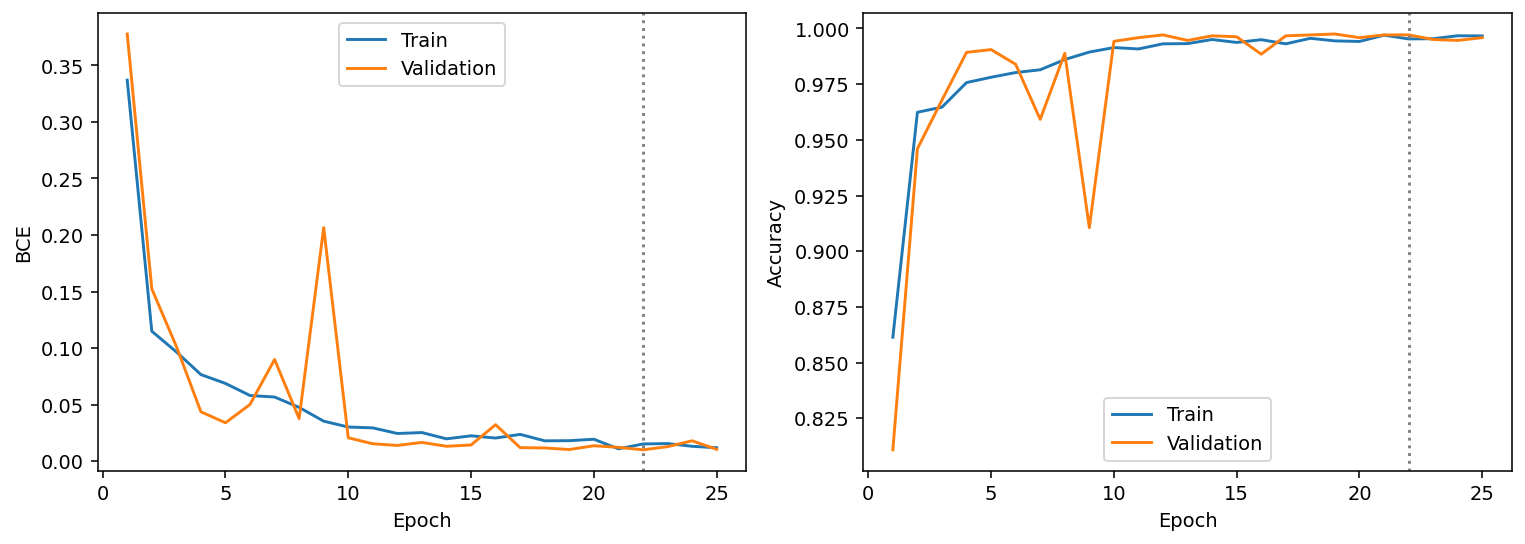

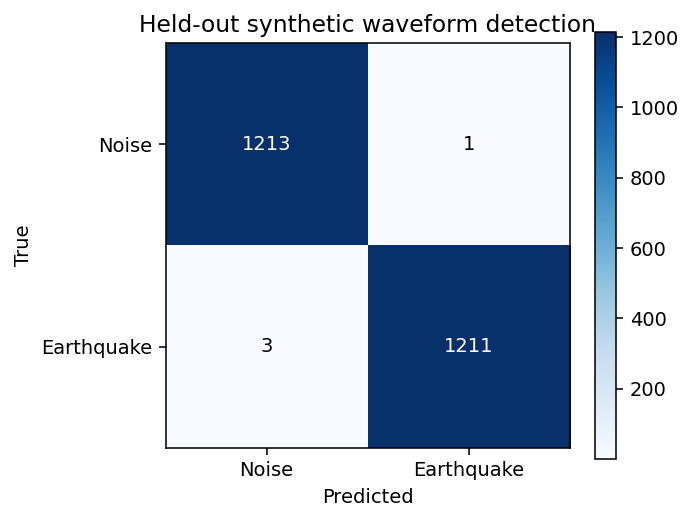

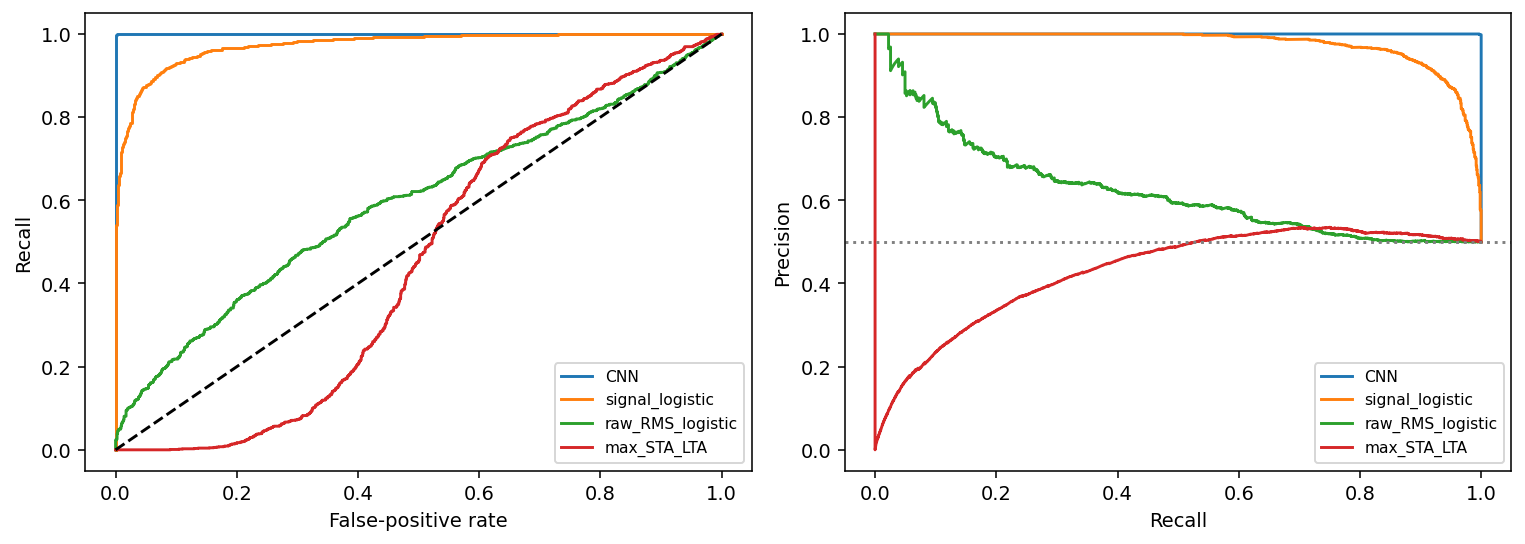

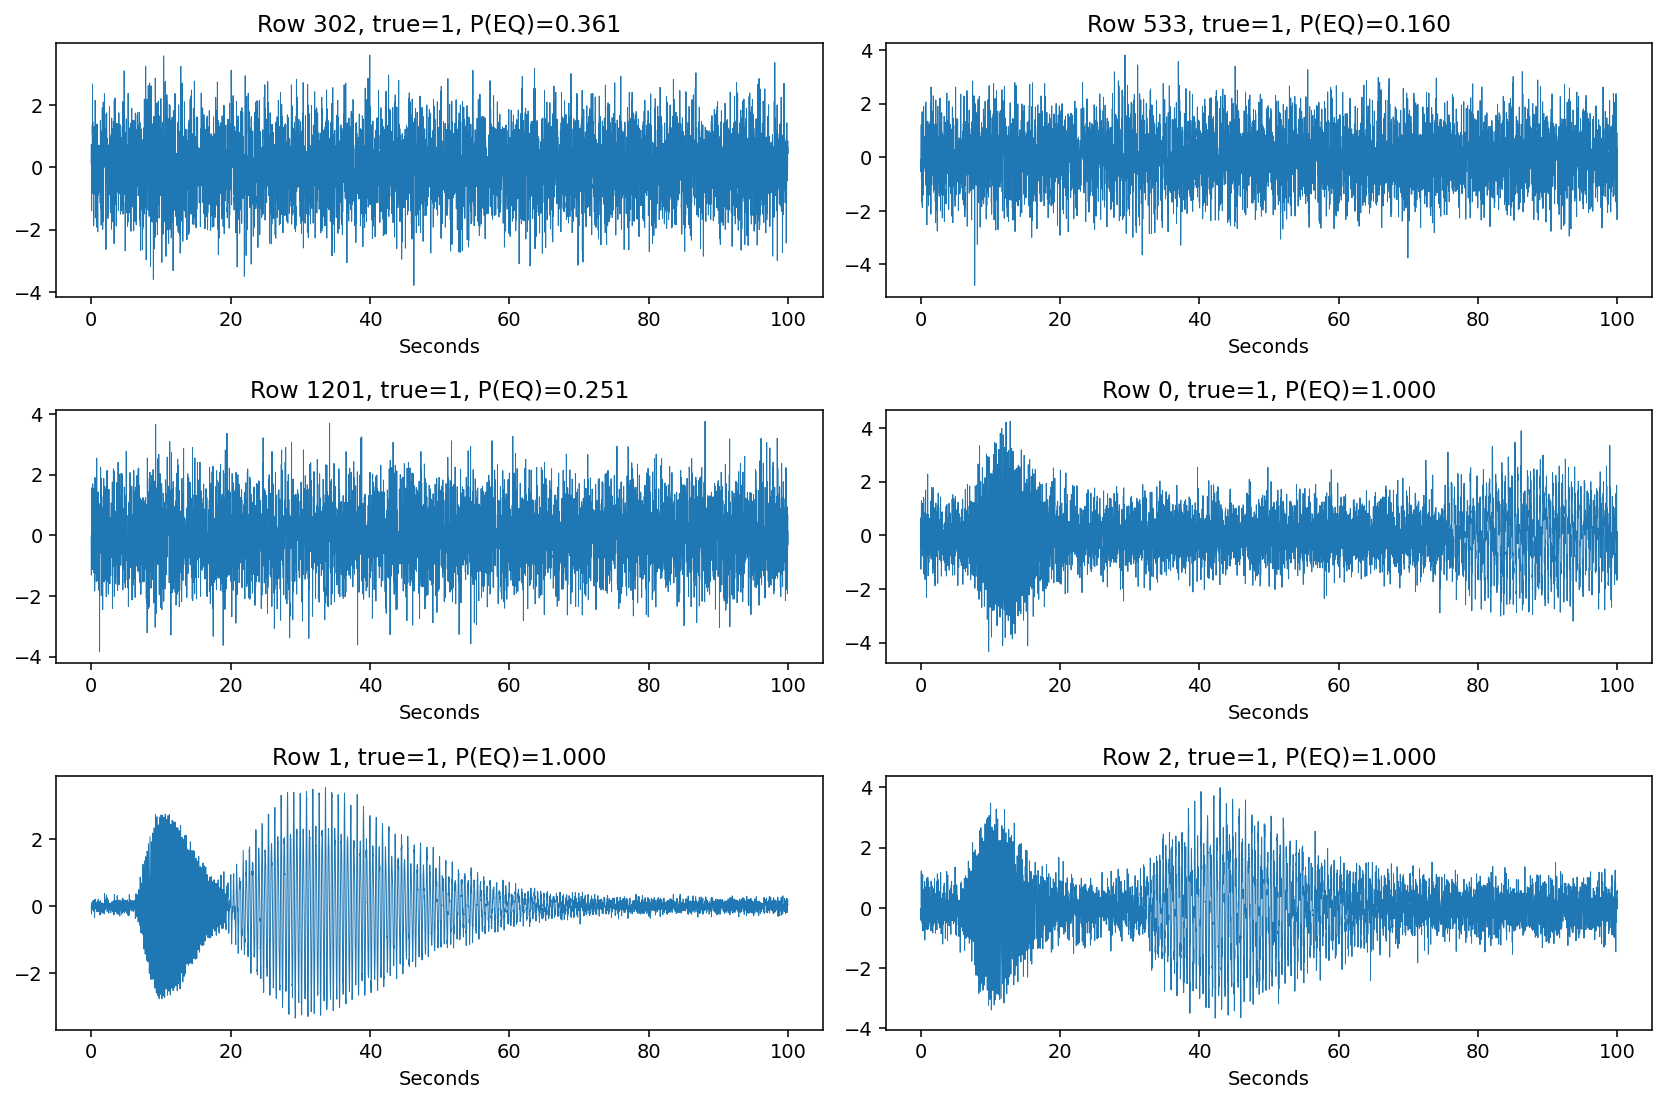

In [9]:
hist=pd.DataFrame(history)
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].plot(hist.epoch,hist.train_loss,label='Train');axes[0].plot(hist.epoch,hist.validation_loss,label='Validation');axes[0].set(ylabel='BCE',xlabel='Epoch');axes[0].legend()
axes[1].plot(hist.epoch,hist.train_accuracy,label='Train');axes[1].plot(hist.epoch,hist.validation_accuracy,label='Validation');axes[1].set(ylabel='Accuracy',xlabel='Epoch');axes[1].legend()
for ax in axes:ax.axvline(best_state['epoch'],color='gray',linestyle=':')
figure('learning_curves.png')
fig,ax=plt.subplots(figsize=(5,4));im=ax.imshow(cm,cmap='Blues');fig.colorbar(im,ax=ax)
for i in range(2):
    for j in range(2):ax.text(j,i,str(cm[i,j]),ha='center',va='center',color='white' if cm[i,j]>cm.max()/2 else 'black')
ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['Noise','Earthquake'],yticklabels=['Noise','Earthquake'],xlabel='Predicted',ylabel='True',title='Held-out synthetic waveform detection')
figure('confusion_matrix.png')
fig,axes=plt.subplots(1,2,figsize=(11,4))
for name,p in predictions['test'].items():
    fpr,tpr,_=roc_curve(labels['test'],p);prec,rec,_=precision_recall_curve(labels['test'],p)
    axes[0].plot(fpr,tpr,label=name);axes[1].plot(rec,prec,label=name)
axes[0].plot([0,1],[0,1],'k--');axes[0].set(xlabel='False-positive rate',ylabel='Recall');axes[0].legend(fontsize=8)
axes[1].axhline(.5,color='gray',linestyle=':');axes[1].set(xlabel='Recall',ylabel='Precision');axes[1].legend(fontsize=8)
figure('roc_pr_curves.png')
wrong=np.flatnonzero((predictions['test']['CNN']>=.5)!=labels['test']);right=np.flatnonzero((predictions['test']['CNN']>=.5)==labels['test'])
selected=np.r_[wrong[:3],right[:6-len(wrong[:3])]]
fig,axes=plt.subplots(3,2,figsize=(12,8))
with h5py.File(PATHS['test'],'r') as f:
    for ax,row in zip(axes.flat,selected):
        x=f[CONFIG['waveform_key']][row];ax.plot(np.arange(10000)/100,x,lw=.5)
        ax.set(title=f'Row {row}, true={int(labels["test"][row])}, P(EQ)={predictions["test"]["CNN"][row]:.3f}',xlabel='Seconds')
figure('example_predictions.png')

## 12. Verification, conclusions and limitations
Reload the saved model and reproduce test probabilities. Recalculate primary metrics from saved prediction files. Verify that every preserved catalog artifact has the original SHA256 hash. Record actual metrics and the complete software environment. Distinguish a verified training pipeline from evidence of field validity.

Limitations: one synthetic generator and vertical component, fixed onset timing, designed noise distributions, shared spectral/envelope templates, artificial 50/50 prevalence and magnitude-dependent synthesis. Pair-disjoint splitting cannot remove generator shortcuts. Normalization uses the whole 100-second trace, so no real-time detection latency claim follows. No real-world, external-generator, station-held-out or temporal generalization test is included. Optional parameter estimation remains untrained for the reasons above; calendar origin time and unique epicentral location are not identifiable from this input alone.

Before BiLSTM, freeze these same detection splits/labels/preprocessing and signal baselines for comparison, then add real recordings or independent synthetic families and variable-onset tests. Keep any future forecasting study separate and use only pre-event information.

## Verified waveform findings — 2026-11-05
The CNN has 4,177 trainable parameters. It completed 25 epochs and restored epoch 22 (validation BCE 0.010031).
Held-out test: accuracy 0.998353, precision 0.999175, recall 0.997529, F1 0.998351, ROC-AUC 0.999995, average precision 0.999995, trapezoidal PR-AUC 0.999995.
Confusion matrix (rows true noise/EQ, columns predicted noise/EQ): [[1213, 1], [3, 1211]].
The five-signal-feature logistic baseline has accuracy 0.915568 and F1 0.913902. This is an in-simulator comparison, not an external field benchmark.

### What the shortcut probes show
- Circular 25 s shift: accuracy 0.997529, AUC 0.999996.
- Time reversal: accuracy 0.997117, AUC 0.999988.
- Spectrum-preserving phase randomization: accuracy 0.941928, AUC 0.973689.
- Pre-onset-noise-only: overall false-positive rate 0.067957; noise taken from earthquake traces 0.071664; noise taken from synthetic-noise traces 0.064250. Its AUC against original source labels is 0.563610; those original labels are diagnostic group labels, not correct event labels after signal removal.

These probes do not establish exactly which physical features are learned. The CNN separates the supplied generated classes; disruption of phase/ordering tests sensitivity to waveform structure, while remaining discrimination can expose generator-specific spectral/background differences. Noise-only probes are derived after full-trace detrending, which itself can leave a class-associated linear-trend imprint; this is another preprocessing shortcut risk. Repetition introduces artificial boundaries. Treat all probes as diagnostics, not causal proof or realistic out-of-distribution performance estimates.

Experiment B is **not trained**. Earthquake magnitude/P/S labels are verified; origin times and coordinates require source-ID joins. Standardization removes absolute amplitude, and waveform shape is generated from known metadata formulas. Absolute origin time and unique epicentral coordinates cannot be recovered from this single clock-free vertical trace. Separate magnitude-inversion/picking studies need explicit baselines and independent data.

Paired-bootstrap accuracy difference (CNN minus signal logistic): 0.082784, 95% interval [0.071664, 0.093904]. This interval covers sampled pairs, not uncertainty across generator families or seeds.


In [10]:
original_p=predictions['test']['CNN'].copy()
model.load_state_dict(torch.load(best_path,map_location=DEVICE,weights_only=False)['model'])
_,reload_p=evaluate('test');assert np.allclose(reload_p,original_p,atol=1e-7,rtol=1e-6)
saved=pd.read_csv(D['metrics']/'test_predictions.csv');recalc=metrics(saved.labels,saved.score_CNN)
cnnrow=table[(table.split=='test')&(table.model=='CNN')].iloc[0]
for k in ['accuracy','precision','recall','f1','roc_auc','average_precision','pr_auc_trapezoidal']:assert np.isclose(recalc[k],cnnrow[k])
preserved=json.loads((RES/'reports'/'preserved_catalog_hashes.json').read_text())
assert all(sha(BASE/p)==digest for p,digest in preserved.items())
assert all((D['models']/p).is_file() for p in ['best.pt','last.pt','preprocessing.json','signal_baselines.pkl'])
assert len(list(D['plots'].glob('*.png')))>=6
verification=dict(epochs=len(history),best_epoch=best_state['epoch'],parameters=PARAMETERS,
    input_shape=[1,10000],output_shape=[1],all_training_samples_once_per_epoch=True,
    saved_model_predictions_match=True,saved_metrics_recomputed=True,catalog_artifacts_unchanged=True,
    label_mapping_and_split_audit_passed=True,figures=len(list(D['plots'].glob('*.png'))))
save(D['reports']/'verification.json',verification)
report=f"""# Waveform CNN detection results — {EID}
Date: 2026-11-05. This is synthetic waveform detection, not future forecasting.
Input: Phase 11 waveforms_standardized, (10000,1), 100 Hz.
Splits: train 11324, validation 2426, test 2428; balanced earthquake/noise.
Parameters: {PARAMETERS}; epochs: {len(history)}; restored epoch: {best_state['epoch']}; GPU: {environment['gpu']}.

## Detection metrics
```
{table[table.split.eq('test')].to_string(index=False)}
```

## Frozen-model shortcut probes
```
{probe_table.to_string(index=False)}
```
Pre-onset-noise probe labels for physical detection are all noise. Its original-label accuracy/AUC only test residual source-class signatures.

## Interpretation constraints
No metadata entered the CNN. Performance on transformed traces and signal baselines indicates possible shortcut reliance but cannot prove physical mechanisms. Synthetic in-distribution test performance is not real-field performance.
Experiment B was audited, not trained: magnitude labels exist but amplitude normalization and simulator inversion confound interpretation; absolute UTC origin time is absent from inputs; single-component traces cannot uniquely identify geographic epicenter. P/S indices are available but P is artificially anchored near six seconds.
Catalog forecasting notebook/results remain byte-for-byte unchanged.
"""
(D['reports']/'final_report.md').write_text(report,encoding='utf-8')
registry=json.loads((MEM/'experiment_registry.json').read_text())
for e in registry['experiments']:
    if e['experiment_id']==EID:e.update(experiment_status='trained_evaluated_pending_external_verification',epochs=len(history),best_epoch=best_state['epoch'],parameters=PARAMETERS,test_metrics=recalc,optional_parameter_estimation='investigated_not_trained')
save(MEM/'experiment_registry.json',registry)
memory(f'W3/W4 completed; W5 external verification pending. {EID}; {len(history)} epochs, best {best_state["epoch"]}.\nModel {best_path.relative_to(BASE)}.\nReport {(D["reports"]/"final_report.md").relative_to(BASE)}. Catalog hashes unchanged.')
print(report)

# Waveform CNN detection results — wavecnn_ccb3b06b3d37
Date: 2026-11-05. This is synthetic waveform detection, not future forecasting.
Input: Phase 11 waveforms_standardized, (10000,1), 100 Hz.
Splits: train 11324, validation 2426, test 2428; balanced earthquake/noise.
Parameters: 4177; epochs: 25; restored epoch: 22; GPU: NVIDIA GeForce RTX 3050 Laptop GPU.

## Detection metrics
```
split            model  samples  accuracy  precision   recall       f1  roc_auc  average_precision  pr_auc_trapezoidal  log_loss   tn   fp  fn   tp  threshold
 test              CNN     2428  0.998353   0.999175 0.997529 0.998351 0.999995           0.999995            0.999995  0.005562 1213    1   3 1211   0.500000
 test  signal_logistic     2428  0.915568   0.932305 0.896211 0.913902 0.973751           0.976230            0.976221  0.211347 1135   79 126 1088   0.500000
 test raw_RMS_logistic     2428  0.578254   0.579299 0.571664 0.575456 0.593738           0.623917            0.623650  0.680251  710  